<a href="https://colab.research.google.com/github/barnanakumarmajhi-cmd/Deep-Learning-/blob/main/5_11_2026_DL3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [2]:
import numpy as np
!pip install tensorflow
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, Input
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.optimizers import Adam
import matplotlib.pyplot as plt
import seaborn as sns

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.9/572.9 MB 18.0 MB/s  0:00:16
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.5/24.5 MB 127.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [tensorflow]


/usr/local/lib/python3.13/dist-packages/jax/_src/cloud_tpu_init.py:90: UserWarning: Transparent hugepages are not enabled. TPU runtime startup and shutdown time should be significantly improved on TPU v5e and newer. If not already set, you may need to enable transparent hugepages in your VM image (sudo sh -c "echo always > /sys/kernel/mm/transparent_hugepage/enabled")
  warnings.warn(


In [3]:
print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


In [4]:
IMG_ROWS, IMG_COLS = 28, 28
NUM_CLASSES = 10
BATCH_SIZE = 128
EPOCHS = 15

In [5]:
print("\n--- Loading Fashion MNIST dataset ---")
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

print(f"x_train shape: {x_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"x_test shape: {x_test.shape}")
print(f"y_test shape: {y_test.shape}")


--- Loading Fashion MNIST dataset ---
29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
x_train shape: (60000, 28, 28)
y_train shape: (60000,)
x_test shape: (10000, 28, 28)
y_test shape: (10000,)



--- Exploratory Data Analysis ---

Sample images from the training set:




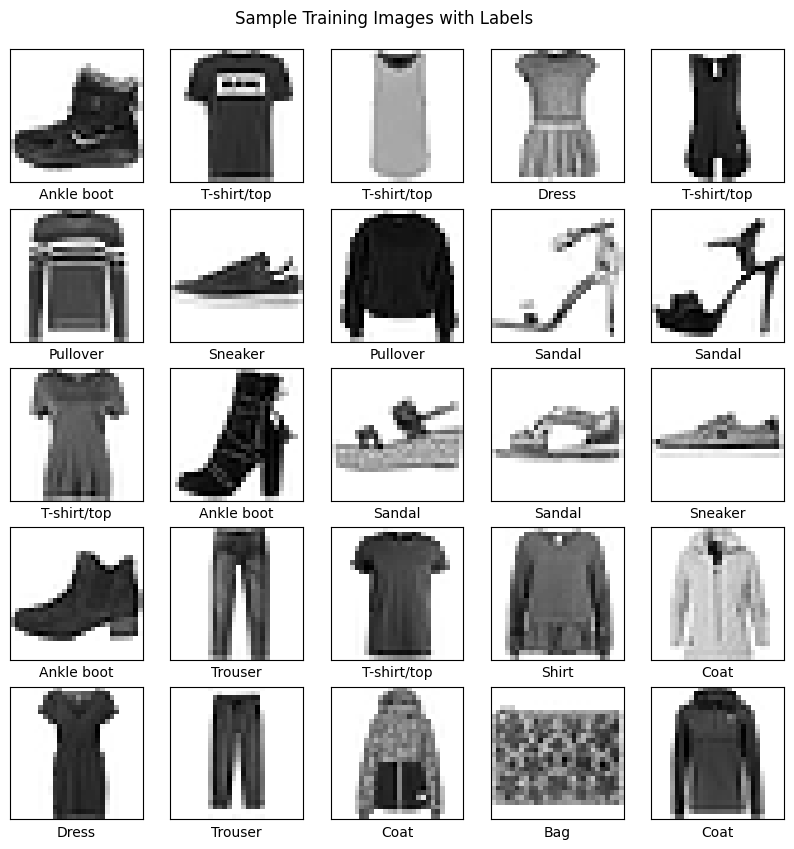

In [6]:
print("\n--- Exploratory Data Analysis ---")

# 4.1 Define Class Names
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

# 4.2 Visualize Sample Images
print("\nSample images from the training set:\n\n")
plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(x_train[i], cmap=plt.cm.binary) # Use binary colormap for grayscale
    plt.xlabel(class_names[y_train[i]])
plt.suptitle("Sample Training Images with Labels", y=0.92)
plt.show()


Label Distribution in Training Set:
{'T-shirt/top': np.int64(6000), 'Trouser': np.int64(6000), 'Pullover': np.int64(6000), 'Dress': np.int64(6000), 'Coat': np.int64(6000), 'Sandal': np.int64(6000), 'Shirt': np.int64(6000), 'Sneaker': np.int64(6000), 'Bag': np.int64(6000), 'Ankle boot': np.int64(6000)}


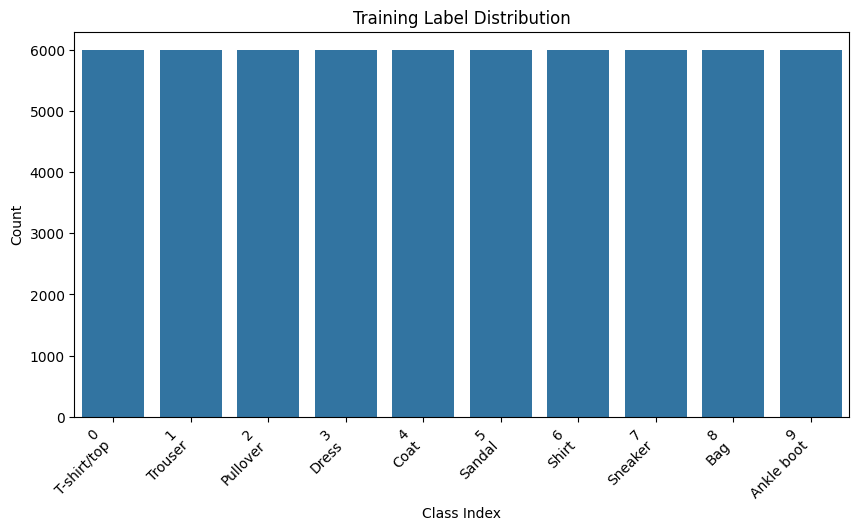

In [7]:
print("\nLabel Distribution in Training Set:")
unique_labels, counts = np.unique(y_train, return_counts=True)
print(dict(zip(class_names, counts)))

plt.figure(figsize=(10, 5))
sns.countplot(x=y_train)
plt.title('Training Label Distribution')
plt.xlabel('Class Index')
plt.ylabel('Count')
plt.xticks(ticks=range(NUM_CLASSES), labels=[f"{i}\n{name}" for i, name in enumerate(class_names)], rotation=45, ha='right')
plt.show()

In [8]:
print("\n--- Preprocessing Data ---")

# 5.1 Reshape Data for CNN (Add Channel Dimension)
# Keras expects (batch_size, rows, cols, channels)
if keras.backend.image_data_format() == 'channels_first':
    x_train_reshaped = x_train.reshape(x_train.shape[0], 1, IMG_ROWS, IMG_COLS)
    x_test_reshaped = x_test.reshape(x_test.shape[0], 1, IMG_ROWS, IMG_COLS)
    input_shape = (1, IMG_ROWS, IMG_COLS)
else: # 'channels_last'
    x_train_reshaped = x_train.reshape(x_train.shape[0], IMG_ROWS, IMG_COLS, 1)
    x_test_reshaped = x_test.reshape(x_test.shape[0], IMG_ROWS, IMG_COLS, 1)
    input_shape = (IMG_ROWS, IMG_COLS, 1)

print(f"Reshaped x_train shape: {x_train_reshaped.shape}")
print(f"Reshaped x_test shape: {x_test_reshaped.shape}")
print(f"Input shape for CNN: {input_shape}")


--- Preprocessing Data ---
Reshaped x_train shape: (60000, 28, 28, 1)
Reshaped x_test shape: (10000, 28, 28, 1)
Input shape for CNN: (28, 28, 1)


In [9]:
# 5.2 Normalize Pixel Values (Scale to 0-1)
x_train_processed = x_train_reshaped.astype('float32') / 255.0
x_test_processed = x_test_reshaped.astype('float32') / 255.0
print(f"Min/Max pixel value after normalization: {x_train_processed.min()}, {x_train_processed.max()}")

Min/Max pixel value after normalization: 0.0, 1.0


In [10]:
# 5.3 One-Hot Encode Labels
y_train_cat = to_categorical(y_train, NUM_CLASSES)
y_test_cat = to_categorical(y_test, NUM_CLASSES)
print(f"Original label example: {y_train[0]}")
print(f"One-hot encoded label example: {y_train_cat[0]}")
print(f"Shape of y_train_cat: {y_train_cat.shape}")
print(f"Shape of y_test_cat: {y_test_cat.shape}")

Original label example: 9
One-hot encoded label example: [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
Shape of y_train_cat: (60000, 10)
Shape of y_test_cat: (10000, 10)


In [11]:
print("\n--- Building the CNN Model ---")
model = Sequential([
    Input(shape=input_shape), # Explicit Input layer

    # Convolutional Block 1
    Conv2D(32, kernel_size=(3, 3), activation='relu', padding='same'),
    MaxPooling2D(pool_size=(2, 2)),
    # Dropout(0.25), # Optional dropout

    # Convolutional Block 2
    Conv2D(64, kernel_size=(3, 3), activation='relu', padding='same'),
    MaxPooling2D(pool_size=(2, 2)),
    # Dropout(0.25), # Optional dropout

    Flatten(), # Flatten the feature maps

    # Dense Classifier Head
    Dense(128, activation='relu'),
    Dropout(0.5), # Dropout for regularization
    Dense(NUM_CLASSES, activation='softmax') # Output layer for multi-class classification
])



--- Building the CNN Model ---


In [12]:
model.compile(optimizer=Adam(learning_rate=0.001),
              loss='categorical_crossentropy', # Use categorical for one-hot labels
              metrics=['accuracy'])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
print("\n--- Training the Model ---")
history = model.fit(x_train_processed,
                    y_train_cat,
                    epochs=EPOCHS,
                    batch_size=BATCH_SIZE,
                    validation_data=(x_test_processed, y_test_cat),
                    verbose=1)


--- Training the Model ---
Epoch 1/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 25s 51ms/step - accuracy: 0.7839 - loss: 0.6022 - val_accuracy: 0.8597 - val_loss: 0.3918
Epoch 2/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 24s 51ms/step - accuracy: 0.8618 - loss: 0.3878 - val_accuracy: 0.8810 - val_loss: 0.3250
Epoch 3/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 24s 51ms/step - accuracy: 0.8808 - loss: 0.3369 - val_accuracy: 0.8927 - val_loss: 0.3007
Epoch 4/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 24s 51ms/step - accuracy: 0.8910 - loss: 0.3044 - val_accuracy: 0.8996 - val_loss: 0.2714
Epoch 5/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 24s 51ms/step - accuracy: 0.9002 - loss: 0.2770 - val_accuracy: 0.9011 - val_loss: 0.2696
Epoch 6/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 24s 51ms/step - accuracy: 0.9059 - loss: 0.2609 - val_accuracy: 0.9085 - val_loss: 0.2514
Epoch 7/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 24s 51ms/step - accuracy: 0.9114 - loss: 0.2448 - val_accuracy: 0.9101 - val_loss: 0.2429
Epoch 8/15
469/469 ━━━━━━━━━━━━━━━━━━━━ 24s 51ms/step - accura

In [14]:
print("\n--- Evaluating the Model ---")
loss, accuracy = model.evaluate(x_test_processed, y_test_cat, verbose=0)
print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f} ({accuracy*100:.2f}%)")


--- Evaluating the Model ---
Test Loss: 0.2237
Test Accuracy: 0.9211 (92.11%)



--- Visualizing Training History ---


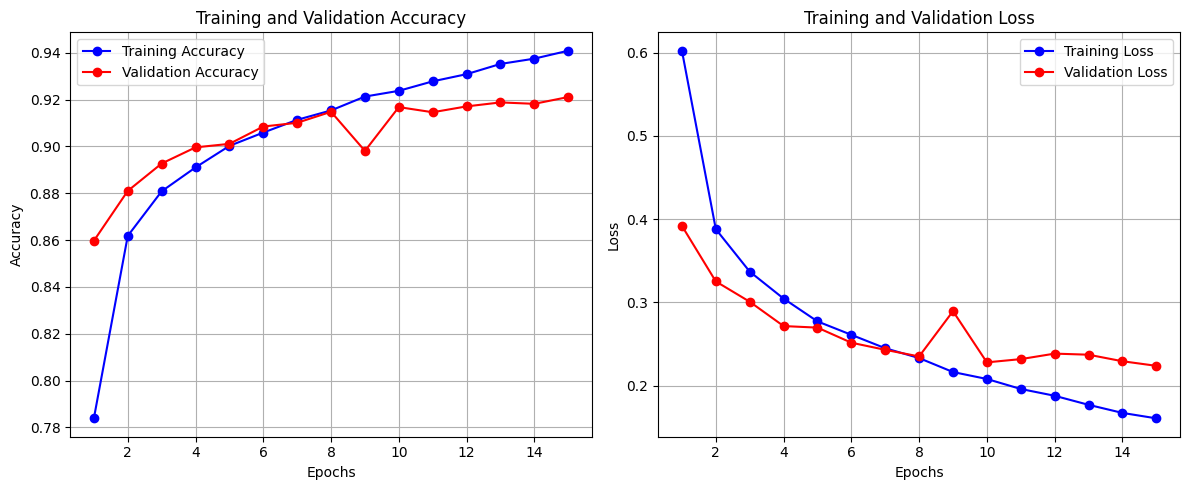

In [16]:
print("\n--- Visualizing Training History ---")
history_dict = history.history

acc = history_dict['accuracy']
val_acc = history_dict['val_accuracy']
loss_values = history_dict['loss']
val_loss_values = history_dict['val_loss']

epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(12, 5))

# Plot Training & Validation Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, 'bo-', label='Training Accuracy')
plt.plot(epochs_range, val_acc, 'ro-', label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Plot Training & Validation Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss_values, 'bo-', label='Training Loss')
plt.plot(epochs_range, val_loss_values, 'ro-', label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()